# Bazowy Model

## Cel:

1) Ustanowienie bazowego modelu klasyfikacji
2) Sprawdzenie metody imputacji KNN
3) Sprawdzenie podstawowych metryk oceny modelu

In [90]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import KNNImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay)

In [4]:
data_file_path = '../data/raw/Dane automotive/CW03carrier.xlsx'

df = pd.read_excel(
    data_file_path,
    dtype_backend='numpy_nullable',
    skiprows=[0,2],
    na_values=['-'],
)

In [12]:
to_drop = df.columns[(df.isnull().mean() > 0.5)].tolist()
print(f'Drop features with more than 50% NaN: {to_drop}')
df = df.drop(columns=to_drop)

Drop features with more than 50% NaN: ['Image', 'Went Thru Tear Down?', 'Reject Desc']


In [19]:
df = df.drop(columns=['Timestamp'])

In [17]:
df['Status'] = df['Status'].map({'Accept':1, 'Reject':0})

In [81]:
X = df.select_dtypes(include=['number']).drop(columns=['Status','Reject Code','MARPOSS Judge Result','Nest ID Verify Cycles'])
y = df['Status']

In [82]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026, stratify=y)

In [95]:
X_train.shape, y_train.value_counts(normalize=True)

((9454, 54),
 Status
 1    0.985086
 0    0.014914
 Name: proportion, dtype: float64)

In [84]:
pipe = Pipeline([
    ('imputer', KNNImputer(n_neighbors=2)),
    ('lr', LogisticRegression(solver='lbfgs', max_iter=800))
])

%time cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy').mean()

CPU times: user 12.8 s, sys: 84.6 ms, total: 12.9 s
Wall time: 1.21 s


np.float64(0.9854031488616364)

In [85]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
print(f'accuracy_score:{accuracy_score(y_test, y_pred)}')

accuracy_score:0.9851924975320829


In [86]:
np.unique(y_pred, return_counts=True)

(array([0, 1]), array([   1, 4051]))

[[   1   60]
 [   0 3991]]


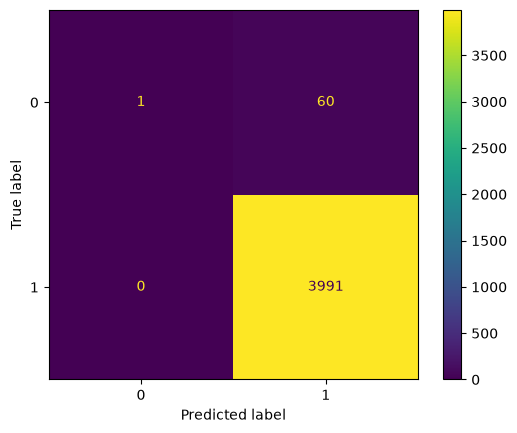

In [92]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
ConfusionMatrixDisplay(cm).plot()
plt.show()

In [89]:
pd.DataFrame({'feat':X_test.columns, 'score':np.abs(pipe.named_steps['lr'].coef_[0])}).sort_values('score', ascending=False)

,feat,score
45,M16 DB Diam To A_D-E_B,2.709822
8,M6 DB Diam To A_D - E_B,2.475143
44,M17 G Diam To D-E,1.347108
7,M7 F Diam To D-E,1.158038
31,M29 E-D To A-B-C PN TP,0.964099
53,Carrier Gage Cycles,0.891995
29,M30 E To A PN TP,0.624503
11,M56 P12,0.621967
1,Cycles,0.614246
36,M24 F-G To D-E CC4,0.577961


## Wnioski:

Niezbalansowanie klas powoduje tendencyjność modelu w stronę liczniejszej klasy

### Następne kroki:

Zaproponować metodę resamplingu do lepszego zbalansowania klas